In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv


In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

train.head()

Train Shape: (891, 12)
Test Shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
train.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


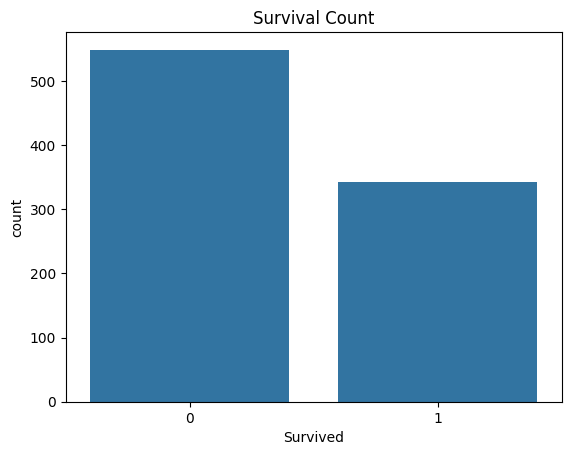

In [5]:
sns.countplot(x='Survived', data=train)

plt.title("Survival Count")
plt.show()


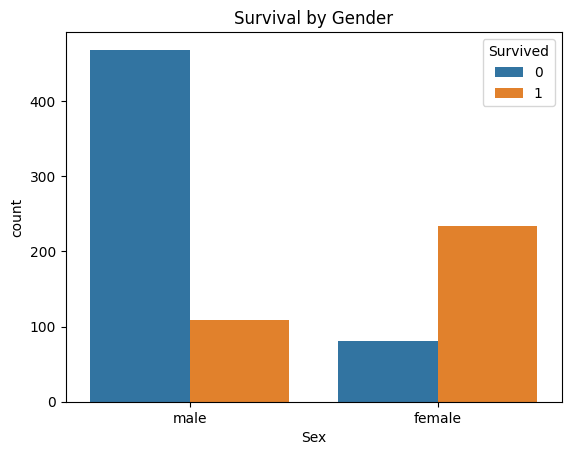

In [6]:
sns.countplot(x='Sex', hue='Survived', data=train)

plt.title("Survival by Gender")
plt.show()

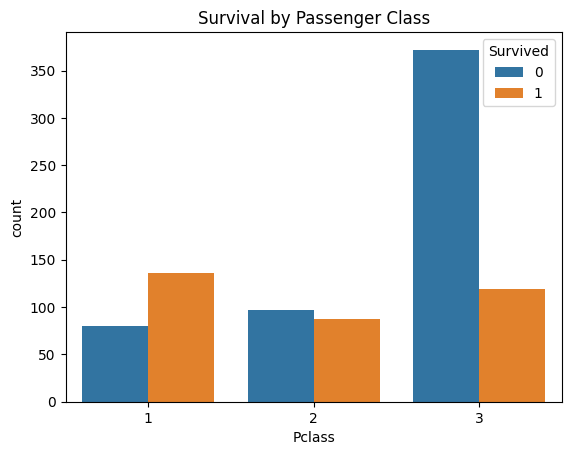

In [7]:
sns.countplot(x='Pclass', hue='Survived', data=train)

plt.title("Survival by Passenger Class")
plt.show()

In [8]:
train['Age'] = train['Age'].fillna(train['Age'].median())
test['Age'] = test['Age'].fillna(test['Age'].median())

train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])
test['Embarked'] = test['Embarked'].fillna(test['Embarked'].mode()[0])

train = train.drop('Cabin', axis=1)
test = test.drop('Cabin', axis=1)

print(train.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [9]:
train['Sex'] = train['Sex'].map({'male':0,'female':1})
test['Sex'] = test['Sex'].map({'male':0,'female':1})

train['Embarked'] = train['Embarked'].map({'S':0,'C':1,'Q':2})
test['Embarked'] = test['Embarked'].map({'S':0,'C':1,'Q':2})

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [11]:
X = train[['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]

y = train['Survived']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [13]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [14]:
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.8268156424581006


In [15]:
print("""
PROJECT INSIGHTS

1. The dataset contains 891 passenger records.

2. Age, Cabin and Embarked columns contained missing values.

3. Female passengers had a much higher survival rate than male passengers.

4. First-class passengers survived more frequently than third-class passengers.

5. Third-class passengers experienced the highest mortality rate.

6. Missing values were handled using median and mode techniques.

7. Random Forest Classifier was used for prediction.

8. The model achieved an accuracy of 82.68%.
""")


PROJECT INSIGHTS

1. The dataset contains 891 passenger records.

2. Age, Cabin and Embarked columns contained missing values.

3. Female passengers had a much higher survival rate than male passengers.

4. First-class passengers survived more frequently than third-class passengers.

5. Third-class passengers experienced the highest mortality rate.

6. Missing values were handled using median and mode techniques.

7. Random Forest Classifier was used for prediction.

8. The model achieved an accuracy of 82.68%.

